# Diffusion: direct and von Neumann stability

**Source mapping:** Vercauteren, Simulation and Modelling 2 (9 July 2025), §5.3.1–5.3.3, pp. 42–45.

Independent study companion; explanations and experiments are newly written. Read in the README order.

## Model and reasoning

For explicit time and central space, c_j^(n+1)=c_j^n+r(c_(j+1)^n-2c_j^n+c_(j-1)^n), r=D*dt/dx². On a periodic grid, a Fourier mode has amplification G=1-4r sin²(theta/2); |G|<=1 for every mode iff 0<=r<=1/2.

The update matrix is circulant and normal, so its 2-norm equals the largest absolute eigenvalue. This connects direct matrix analysis to Fourier analysis in this particular setting; eigenvalues alone are not sufficient for arbitrary nonnormal matrices. Backward Euler instead has G=1/(1+4r sin²(theta/2)), so diffusion is unconditionally stable, but still has time error.

## Reproducible experiment

Predict the plot before running. All parameters below are illustrative, not measured environmental data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True})
rng = np.random.default_rng(42)

0.4 matrix norm: 1.0
0.6 matrix norm: 1.4000000000000001


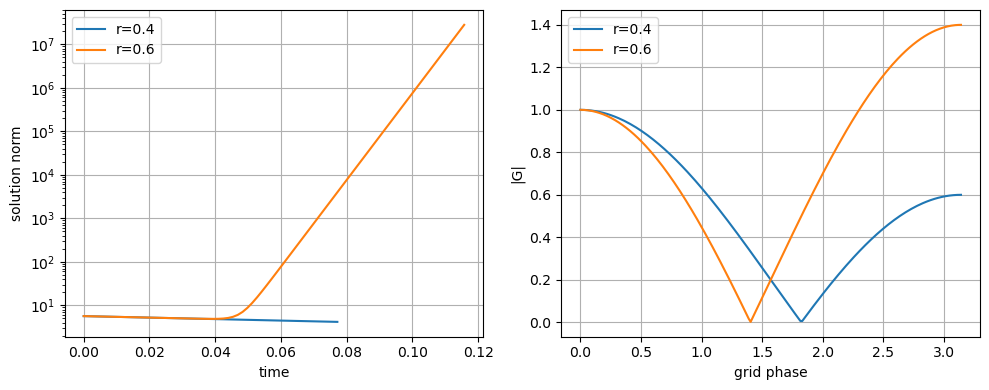

In [2]:
N=64;dx=1/N;D=.1;x=np.arange(N)*dx
L=(np.roll(np.eye(N),1,axis=1)-2*np.eye(N)+np.roll(np.eye(N),-1,axis=1))/dx**2
fig,ax=plt.subplots(1,2,figsize=(10,4))
for r in [.4,.6]:
 dt=r*dx*dx/D;M=np.eye(N)+dt*D*L
 c=np.sin(2*np.pi*x)+1e-5*(-1.)**np.arange(N);history=[]
 for _ in range(80):history.append(np.linalg.norm(c));c=M@c
 ax[0].semilogy(np.arange(80)*dt,history,label=f"r={r}")
 print(r,"matrix norm:",np.linalg.norm(M,2))
theta=np.linspace(0,np.pi,200)
for r in [.4,.6]:ax[1].plot(theta,abs(1-4*r*np.sin(theta/2)**2),label=f"r={r}")
ax[0].set(xlabel="time",ylabel="solution norm");ax[1].set(xlabel="grid phase",ylabel="|G|");ax[0].legend();ax[1].legend();plt.tight_layout();plt.show()
assert np.linalg.norm(np.eye(N)+.4*dx*dx*L,2)<1+1e-12

## Read the result

The tiny alternating perturbation reveals an unstable high-frequency mode that a smooth initial state could temporarily hide. Halving dx requires quartering dt for this explicit diffusion scheme.

## Your turn

Run implicit Euler at r=5 and compare to the exact decaying sine at the same final time. Measure accuracy separately from stability.

Record: prediction → observation → explanation. A successful assertion checks this example; it is not a general proof.